# EMBER 2018 – Exploratory Data Analysis

This notebook looks at the raw EMBER 2018 (v2) feature files in `data/raw/ember2018/`.
Each line of a `.jsonl` file is one Windows PE file, described by its **pre-extracted static features**. No executables are included.

To keep it fast on a laptop, only the first `N_ROWS` lines of each file are loaded.

In [1]:
import json
from collections import Counter
from itertools import islice
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

pd.set_option("display.max_columns", 60)
pd.set_option("display.width", 160)

# Works whether Jupyter is started from the repo root or from notebooks/
ROOT = Path.cwd() if (Path.cwd() / "data").exists() else Path.cwd().parent
DATA_DIR = ROOT / "data" / "raw" / "ember2018"
N_ROWS = 5000  # rows read per file

files = sorted(DATA_DIR.glob("*.jsonl"))
pd.DataFrame({"file": [f.name for f in files],
              "size_GB": [round(f.stat().st_size / 1e9, 2) for f in files]})

,file,size_GB
0,test_features.jsonl,1.87
1,train_features_0.jsonl,0.57
2,train_features_1.jsonl,1.66
3,train_features_2.jsonl,1.30
4,train_features_3.jsonl,1.38
5,train_features_4.jsonl,1.32
6,train_features_5.jsonl,1.85


## 1. Row counts per file
This counts every line in the files, so it takes about a minute. Skip it if you don't need it.

In [2]:
def count_lines(path):
    with open(path, "rb") as f:
        return sum(buf.count(b"\n") for buf in iter(lambda: f.read(1 << 24), b""))

row_counts = {f.name: count_lines(f) for f in files}
pd.Series(row_counts, name="rows").to_frame().assign(total=lambda d: d.rows.sum())

,rows,total
test_features.jsonl,200000,1000000
train_features_0.jsonl,50000,1000000
train_features_1.jsonl,158158,1000000
train_features_2.jsonl,127891,1000000
train_features_3.jsonl,129195,1000000
train_features_4.jsonl,132182,1000000
train_features_5.jsonl,202574,1000000


## 2. Load a sample

In [3]:
def read_jsonl(path, n):
    with open(path) as f:
        return [json.loads(line) for line in islice(f, n)]

records = []
for f in files:
    for r in read_jsonl(f, N_ROWS):
        r["_split"] = "test" if f.name.startswith("test") else "train"
        r["_file"] = f.name
        records.append(r)

df = pd.DataFrame(records)
print(df.shape)
df.columns.tolist()

(35000, 16)


['sha256',
 'md5',
 'appeared',
 'label',
 'avclass',
 'histogram',
 'byteentropy',
 'strings',
 'general',
 'header',
 'section',
 'imports',
 'exports',
 'datadirectories',
 '_split',
 '_file']

## 3. Top-level columns: type and an example value

In [4]:
example = df.iloc[0]
pd.DataFrame({
    "python_type": [type(example[c]).__name__ for c in df.columns],
    "example": [str(example[c])[:100] for c in df.columns],
}, index=df.columns)

,python_type,example
sha256,str,163ced46c18ef09d8e2f0ee4b16decf74a533f22ba3b59...
md5,str,c747678f13ec94deffeab0c44481a988
appeared,str,2018-11
label,int64,1
avclass,str,xtrat
histogram,list,"[54733, 8020, 5960, 5467, 5567, 4804, 4058, 52..."
byteentropy,list,"[22510, 0, 0, 0, 0, 0, 2, 6, 0, 2, 4, 0, 0, 2,..."
strings,dict,"{'numstrings': 4029, 'avlength': 5.70340034748..."
general,dict,"{'size': 966594, 'vsize': 2072576, 'has_debug'..."
header,dict,"{'coff': {'timestamp': 1504401044, 'machine': ..."


In [5]:
# Keys inside each nested (dict) column
for col in df.columns:
    if isinstance(example[col], dict):
        print(f"{col}: {list(example[col].keys())}")

strings: ['numstrings', 'avlength', 'printabledist', 'printables', 'entropy', 'paths', 'urls', 'registry', 'MZ']
general: ['size', 'vsize', 'has_debug', 'exports', 'imports', 'has_relocations', 'has_resources', 'has_signature', 'has_tls', 'symbols']
header: ['coff', 'optional']
section: ['entry', 'sections']
imports: ['kernel32.dll', 'comctl32.dll']


## 4. Labels
`-1` = unlabeled, `0` = benign, `1` = malicious. Unlabeled rows are dropped for supervised learning.

In [6]:
label_counts = pd.crosstab(df["_file"], df["label"], margins=True)
label_counts

label,-1,0,1,All
_file,,,,
test_features.jsonl,0,2510,2490,5000
train_features_0.jsonl,0,5000,0,5000
train_features_1.jsonl,1315,1750,1935,5000
train_features_2.jsonl,1338,1856,1806,5000
train_features_3.jsonl,1383,1910,1707,5000
train_features_4.jsonl,1279,1820,1901,5000
train_features_5.jsonl,1329,1523,2148,5000
All,6644,16369,11987,35000


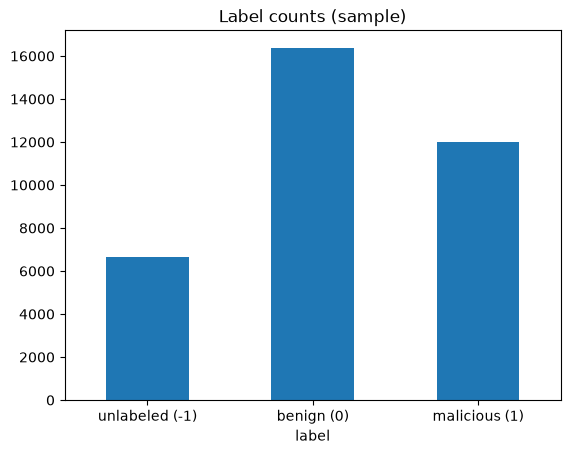

In [7]:
ax = df["label"].value_counts().sort_index().plot.bar(title="Label counts (sample)")
ax.set_xticklabels(["unlabeled (-1)", "benign (0)", "malicious (1)"], rotation=0);

## 5. `appeared` (first-seen month): the basis for the time split

label,-1,0,1
appeared,,,
2006-12,0,1,0
2007-01,0,1,0
2007-02,0,3,0
2007-04,0,1,0
2007-08,0,2,0
...,...,...,...
2018-03,1338,1856,1806
2018-05,1383,1910,1707
2018-07,1279,1820,1901


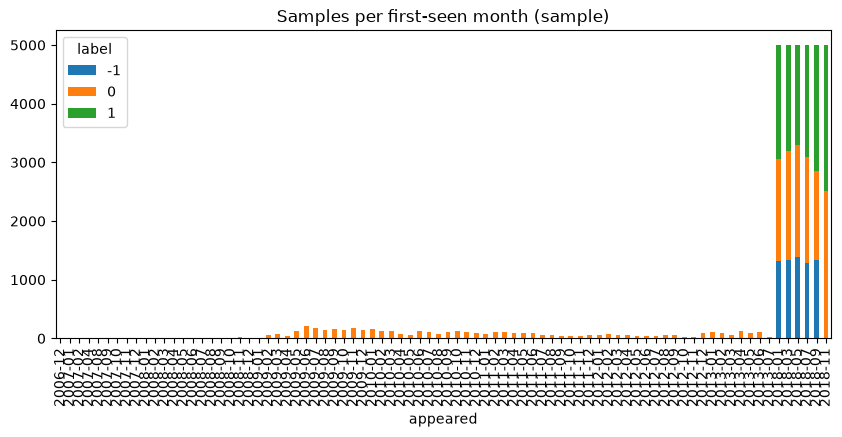

In [8]:
by_month = pd.crosstab(df["appeared"], df["label"])
display(by_month)
by_month.plot.bar(stacked=True, figsize=(10, 4), title="Samples per first-seen month (sample)");

In [9]:
df.groupby("_split")["appeared"].agg(["min", "max"])

,min,max
_split,,
test,2018-11,2018-11
train,2006-12,2018-09


## 6. Malware families (`avclass`)

In [10]:
mal = df[df["label"] == 1]
print("distinct families:", mal["avclass"].nunique(), "| empty:", (mal["avclass"] == "").sum())
mal["avclass"].value_counts().head(20)

distinct families: 712 | empty: 383


avclass
installmonster    728
xtrat             682
zusy              645
zbot              484
ramnit            409
fareit            402
                  383
adposhel          363
high              353
emotet            351
sality            350
sivis             264
flystudio         246
startsurf         189
bladabindi        167
upatre            166
ursnif            148
lethic            128
wannacry          125
gamarue           124
Name: count, dtype: int64

## 7. Flattened scalar feature groups
`general`, `strings`, `header.coff`, `header.optional`

In [11]:
flat = pd.json_normalize(df[["general", "strings", "header"]].to_dict("records"))
# keep scalar columns only (drop lists/dicts such as strings.printabledist, header.coff.characteristics)
scalar_cols = [c for c in flat.columns if not isinstance(flat[c].iloc[0], (list, dict))]
flat = flat[scalar_cols]
print(flat.shape)
flat.dtypes.value_counts()

(35000, 33)


int64      28
str         3
float64     2
Name: count, dtype: int64

In [12]:
num = flat.select_dtypes("number")
num.describe().T.assign(n_missing=num.isna().sum())

,count,mean,std,min,25%,50%,75%,max,n_missing
general.size,35000.0,1.463097e+06,4.794508e+06,326.000000,9.700725e+04,4.110845e+05,1.204814e+06,3.253537e+08,0
general.vsize,35000.0,1.768969e+06,1.013086e+07,512.000000,9.830400e+04,3.522560e+05,1.220608e+06,5.792809e+08,0
general.has_debug,35000.0,3.889714e-01,4.875238e-01,0.000000,0.000000e+00,0.000000e+00,1.000000e+00,1.000000e+00,0
general.exports,35000.0,3.386717e+01,4.883342e+02,0.000000,0.000000e+00,0.000000e+00,0.000000e+00,2.919700e+04,0
general.imports,35000.0,1.087347e+02,2.087234e+02,0.000000,1.000000e+00,5.300000e+01,1.530000e+02,1.105200e+04,0
general.has_relocations,35000.0,5.284571e-01,4.991967e-01,0.000000,0.000000e+00,1.000000e+00,1.000000e+00,1.000000e+00,0
general.has_resources,35000.0,8.989714e-01,3.013709e-01,0.000000,1.000000e+00,1.000000e+00,1.000000e+00,1.000000e+00,0
general.has_signature,35000.0,2.335143e-01,4.230727e-01,0.000000,0.000000e+00,0.000000e+00,0.000000e+00,1.000000e+00,0
general.has_tls,35000.0,1.984286e-01,3.988223e-01,0.000000,0.000000e+00,0.000000e+00,0.000000e+00,1.000000e+00,0
general.symbols,35000.0,4.195917e+01,1.157675e+03,0.000000,0.000000e+00,0.000000e+00,0.000000e+00,1.316600e+05,0


In [13]:
# Categorical (string) header fields
for c in flat.select_dtypes(exclude="number").columns:
    print(f"\n{c}:\n{flat[c].value_counts().head(8).to_string()}")


header.coff.machine:
header.coff.machine
I386     32191
AMD64     2755
ARMNT       20
IA64        12
???         11
ARM          3
THUMB        2
SH3          2

header.optional.subsystem:
header.optional.subsystem
WINDOWS_GUI                 29492
WINDOWS_CUI                  5009
NATIVE                        321
EFI_BOOT_SERVICE_DRIVER       126
UNKNOWN                        17
WINDOWS_CE_GUI                 15
WINDOWS_BOOT_APPLICATION        8
EFI_RUNTIME_DRIVER              8

header.optional.magic:
header.optional.magic
PE32         32220
PE32_PLUS     2780


## 8. List and dict features

In [14]:
summary = pd.DataFrame({
    "histogram_len": df["histogram"].map(len),
    "byteentropy_len": df["byteentropy"].map(len),
    "printabledist_len": df["strings"].map(lambda s: len(s["printabledist"])),
    "n_sections": df["section"].map(lambda s: len(s["sections"])),
    "n_import_libs": df["imports"].map(len),
    "n_imported_funcs": df["imports"].map(lambda d: sum(len(v) for v in d.values())),
    "n_exports": df["exports"].map(len),
    "n_datadirectories": df["datadirectories"].map(len),
})
summary.describe().T

,count,mean,std,min,25%,50%,75%,max
histogram_len,35000.0,256.000000,0.000000,256.0,256.0,256.0,256.0,256.0
byteentropy_len,35000.0,256.000000,0.000000,256.0,256.0,256.0,256.0,256.0
printabledist_len,35000.0,96.000000,0.000000,96.0,96.0,96.0,96.0,96.0
n_sections,35000.0,4.831571,2.378582,0.0,3.0,4.0,6.0,59.0
n_import_libs,35000.0,5.732971,6.391037,0.0,1.0,4.0,9.0,163.0
n_imported_funcs,35000.0,127.961286,1931.742920,0.0,1.0,55.0,157.0,358846.0
n_exports,35000.0,33.867171,488.334206,0.0,0.0,0.0,0.0,29197.0
n_datadirectories,35000.0,15.000000,0.000000,15.0,15.0,15.0,15.0,15.0


In [15]:
# Example section entries
pd.DataFrame(df["section"].iloc[0]["sections"])

,name,size,entropy,vsize,props
0,,94208,7.959737,204800,"[CNT_INITIALIZED_DATA, MEM_EXECUTE, MEM_READ, ..."
1,.rsrc,16384,7.523454,27980,"[CNT_INITIALIZED_DATA, MEM_READ, MEM_WRITE]"
2,.idata,4096,0.220958,4096,"[CNT_INITIALIZED_DATA, MEM_READ, MEM_WRITE]"
3,,4096,0.042169,995328,"[CNT_INITIALIZED_DATA, MEM_EXECUTE, MEM_READ, ..."
4,nhgxrnnn,831488,7.861370,831488,"[CNT_INITIALIZED_DATA, MEM_EXECUTE, MEM_READ, ..."
5,zgwhklkc,4096,0.712098,4096,"[CNT_INITIALIZED_DATA, MEM_EXECUTE, MEM_READ, ..."


In [16]:
lib_counts = Counter(lib.lower() for d in df["imports"] for lib in d)
pd.Series(lib_counts).sort_values(ascending=False).head(20)

kernel32.dll    23929
user32.dll      18137
advapi32.dll    15230
shell32.dll     11706
gdi32.dll       11417
ole32.dll       10990
oleaut32.dll     9647
comctl32.dll     9574
version.dll      5454
mscoree.dll      4758
msvcrt.dll       4583
shlwapi.dll      4171
winspool.drv     3267
comdlg32.dll     3232
wininet.dll      2869
ws2_32.dll       2776
winmm.dll        2702
ntdll.dll        1524
msvbvm60.dll     1522
oleacc.dll       1409
dtype: int64

## 9. Feature differences by label

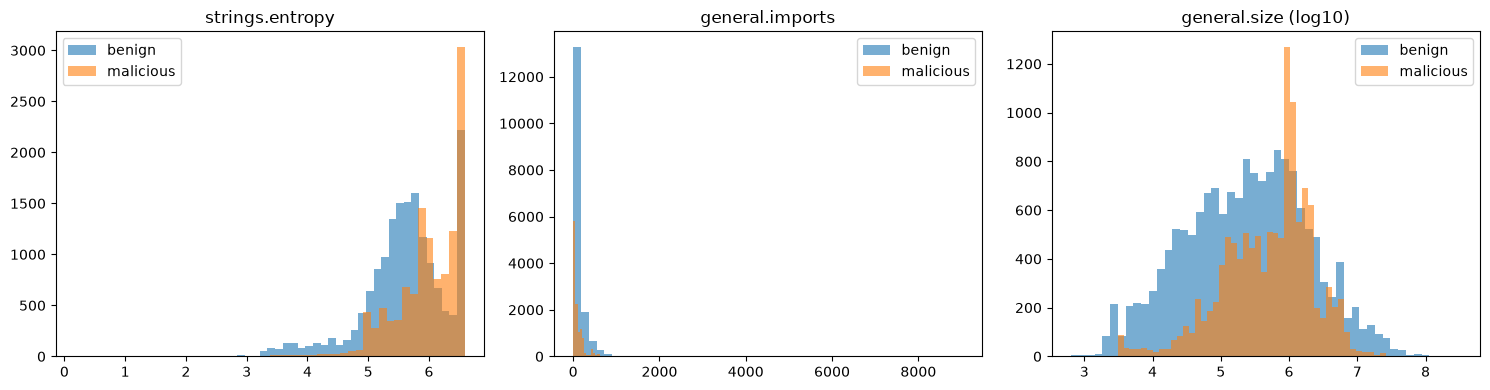

In [17]:
lab = df[df["label"] >= 0].reset_index(drop=True)
lab_flat = pd.json_normalize(lab[["general", "strings"]].to_dict("records"))
lab_flat["label"] = lab["label"].map({0: "benign", 1: "malicious"})

fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, col in zip(axes, ["strings.entropy", "general.imports", "general.size"]):
    for name, g in lab_flat.groupby("label"):
        vals = g[col]
        if col == "general.size":
            vals = np.log10(vals + 1)
        ax.hist(vals, bins=50, alpha=0.6, label=name)
    ax.set_title(col + (" (log10)" if col == "general.size" else ""))
    ax.legend()
plt.tight_layout()

## 10. Feature scales
Value ranges vary over many orders of magnitude, so linear models will need scaling.

In [18]:
rng = num.agg(["min", "max"]).T
rng["log10_range"] = np.log10(rng["max"].abs() + 1)
rng.sort_values("log10_range", ascending=False).head(15)

,min,max,log10_range
header.optional.sizeof_code,0.000000,4.294967e+09,9.632960
header.coff.timestamp,0.000000,4.294951e+09,9.632958
header.optional.sizeof_heap_commit,0.000000,8.820887e+08,8.945512
general.vsize,512.000000,5.792809e+08,8.762889
general.size,326.000000,3.253537e+08,8.512356
strings.printables,11.000000,2.179051e+07,7.338267
header.optional.sizeof_headers,384.000000,5.873664e+06,6.768909
strings.numstrings,1.000000,1.572261e+06,6.196525
general.symbols,0.000000,1.316600e+05,5.119457
header.optional.major_image_version,0.000000,6.542600e+04,4.815757
